<a href="https://colab.research.google.com/github/NoelAR1103/DNA-sequence-classification-using-k-mers-and-Machine-learning/blob/main/DNAseqCLASS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q biopython scikit-learn

from Bio import Entrez, SeqIO

# 1. Tell NCBI who is requesting the data (required by NCBI rules)
Entrez.email = "noeldixon1111@gmail.com"

# 2. Helper function to fetch real DNA sequences from NCBI GenBank
def fetch_dna_from_ncbi(search_term, label, max_records=40):
    print(f"Downloading {max_records} sequences for {label}...")
    # Search NCBI nucleotide database
    handle = Entrez.esearch(db="nucleotide", term=search_term, retmax=max_records)
    id_list = Entrez.read(handle)["IdList"]
    handle.close()

    # Download the actual FASTA sequences
    fetch_handle = Entrez.efetch(db="nucleotide", id=id_list, rettype="fasta", retmode="text")
    records = list(SeqIO.parse(fetch_handle, "fasta"))
    fetch_handle.close()

    # Keep clean sequences between 300 and 3000 bases long
    clean_data = []
    for rec in records:
        seq_str = str(rec.seq).upper()
        if 300 <= len(seq_str) <= 3000:
            clean_data.append((seq_str, label))
    return clean_data

# 3. Download 3 distinct biological classes from NCBI
bacteria_seqs = fetch_dna_from_ncbi("Escherichia coli[Organism] AND 16S ribosomal RNA[Title]", "Bacteria", 50)
virus_seqs    = fetch_dna_from_ncbi("Severe acute respiratory syndrome coronavirus 2[Organism] AND spike[Title]", "Virus", 50)
human_seqs    = fetch_dna_from_ncbi("Homo sapiens[Organism] AND BRCA1[Gene] AND mRNA[Filter]", "Human", 50)

dataset = bacteria_seqs + virus_seqs + human_seqs
print(f"\nTotal clean DNA sequences collected: {len(dataset)}")
print(f"Sample sequence (first 60 bases): {dataset[0][0][:60]}... -> Label: {dataset[0][1]}")


Total clean DNA sequences collected: 96
Sample sequence (first 60 bases): CAAGTTTGATCATGGCTCAGATTGAACGCTGGCGGCAGGCCTAACACATGCAAGTCGAAC... -> Label: Bacteria


In [2]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# 1. Function to chop any DNA sequence into overlapping k-mers (default k=4)
def get_kmers(sequence, k=4):
    kmers = []
    # Slide a window of size k from start to end of the sequence
    for i in range(len(sequence) - k + 1):
        word = sequence[i : i + k]
        kmers.append(word)
    return " ".join(kmers)  # Join into a space-separated "sentence" of DNA words

# Test our function on a tiny example first so you can see how it works!
sample_dna = "ATGCGTA"
print("Sample DNA:", sample_dna)
print("4-mers sentence:", get_kmers(sample_dna, k=4))

# 2. Convert every sequence in our NCBI dataset into a 4-mer sentence
dna_sentences = [get_kmers(seq, k=4) for seq, label in dataset]
labels = [label for seq, label in dataset]

# 3. Convert those DNA "sentences" into a table of word counts (4^4 = 256 possible 4-letter words)
vectorizer = CountVectorizer(ngram_range=(1, 1))
X = vectorizer.fit_transform(dna_sentences)

print(f"\nConverted {len(dataset)} DNA sequences into a numerical matrix of shape: {X.shape}")
print("First 10 DNA 4-mer features:", vectorizer.get_feature_names_out()[:10])

Sample DNA: ATGCGTA
4-mers sentence: ATGC TGCG GCGT CGTA

Converted 96 DNA sequences into a numerical matrix of shape: (96, 304)
First 10 DNA 4-mer features: ['aaaa' 'aaac' 'aaag' 'aaat' 'aaca' 'aacc' 'aacg' 'aact' 'aaga' 'aagc']


Training sequences: 76 | Unseen Testing sequences: 20

Model Accuracy on Unseen DNA Sequences: 95.00%

--- DETAILED CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

    Bacteria       0.91      1.00      0.95        10
       Virus       1.00      0.90      0.95        10

    accuracy                           0.95        20
   macro avg       0.95      0.95      0.95        20
weighted avg       0.95      0.95      0.95        20



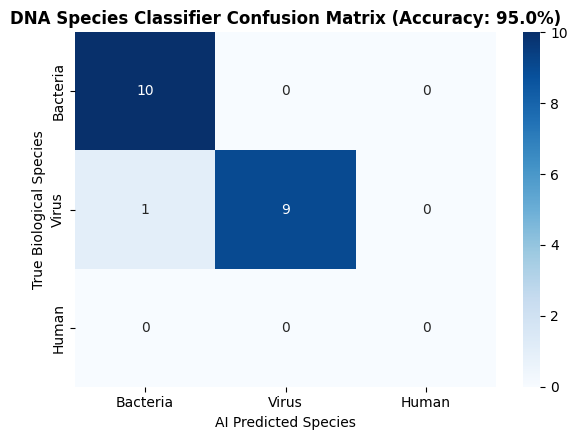

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Split the 96 sequences into 80% Training data and 20% Unseen Testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, labels, test_size=0.20, random_state=42, stratify=labels
)
print(f"Training sequences: {X_train.shape[0]} | Unseen Testing sequences: {X_test.shape[0]}")

# 2. Create and train the Naive Bayes Machine Learning model
model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)

# 3. Ask the trained AI to predict the species of the 20 unseen DNA sequences
predictions = model.predict(X_test)

# 4. Grade the model's accuracy
acc = accuracy_score(y_test, predictions) * 100
print(f"\nModel Accuracy on Unseen DNA Sequences: {acc:.2f}%\n")
print("--- DETAILED CLASSIFICATION REPORT ---")
print(classification_report(y_test, predictions))

# 5. Plot a visual Confusion Matrix heatmap
cm = confusion_matrix(y_test, predictions, labels=["Bacteria", "Virus", "Human"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Bacteria", "Virus", "Human"],
            yticklabels=["Bacteria", "Virus", "Human"])
plt.title(f"DNA Species Classifier Confusion Matrix (Accuracy: {acc:.1f}%)", fontweight="bold")
plt.xlabel("AI Predicted Species")
plt.ylabel("True Biological Species")
plt.tight_layout()
plt.savefig("dna_classifier_confusion_matrix.png", dpi=300)
plt.show()

Clean Human HBB sequences collected: 11

3-Class Model Accuracy (Bacteria vs. Virus vs. Human): 95.45%

              precision    recall  f1-score   support

    Bacteria       0.91      1.00      0.95        10
       Human       1.00      1.00      1.00         2
       Virus       1.00      0.90      0.95        10

    accuracy                           0.95        22
   macro avg       0.97      0.97      0.97        22
weighted avg       0.96      0.95      0.95        22



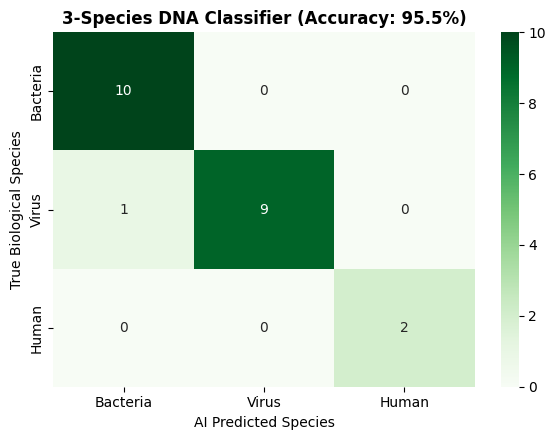


--- TESTING LIVE MYSTERY SEQUENCES ---
Predicted Origin: Bacteria | Confidence: {np.str_('Bacteria'): np.float64(100.0), np.str_('Human'): np.float64(0.0), np.str_('Virus'): np.float64(0.0)}
Predicted Origin: Human | Confidence: {np.str_('Bacteria'): np.float64(0.0), np.str_('Human'): np.float64(100.0), np.str_('Virus'): np.float64(0.0)}


In [4]:
# 1. Fetch Human Beta-Globin (HBB) mRNA sequences (~620 bp each, fitting our 300-3000 bp window!)
human_seqs = fetch_dna_from_ncbi("Homo sapiens[Organism] AND HBB[Gene] AND mRNA[Filter]", "Human", 50)
print(f"Clean Human HBB sequences collected: {len(human_seqs)}")

# 2. Rebuild balanced 3-class dataset (Bacteria + Virus + Human)
full_dataset = bacteria_seqs + virus_seqs + human_seqs
dna_sentences = [get_kmers(seq, k=4) for seq, label in full_dataset]
labels = [label for seq, label in full_dataset]

X_full = vectorizer.fit_transform(dna_sentences)
X_train, X_test, y_train, y_test = train_test_split(
    X_full, labels, test_size=0.20, random_state=42, stratify=labels
)

# 3. Retrain Multinomial Naive Bayes on all 3 species
model = MultinomialNB(alpha=0.1)
model.fit(X_train, y_train)
predictions = model.predict(X_test)

acc = accuracy_score(y_test, predictions) * 100
print(f"\n3-Class Model Accuracy (Bacteria vs. Virus vs. Human): {acc:.2f}%\n")
print(classification_report(y_test, predictions))

# 4. Plot updated 3x3 Confusion Matrix
cm = confusion_matrix(y_test, predictions, labels=["Bacteria", "Virus", "Human"])
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=["Bacteria", "Virus", "Human"],
            yticklabels=["Bacteria", "Virus", "Human"])
plt.title(f"3-Species DNA Classifier (Accuracy: {acc:.1f}%)", fontweight="bold")
plt.xlabel("AI Predicted Species")
plt.ylabel("True Biological Species")
plt.tight_layout()
plt.savefig("dna_3species_confusion_matrix.png", dpi=300)
plt.show()

# 5. Live Inference Function: Classify ANY unknown DNA sequence!
def predict_mystery_dna(dna_seq):
    kmer_str = get_kmers(dna_seq.upper(), k=4)
    vec = vectorizer.transform([kmer_str])
    pred_species = model.predict(vec)[0]
    probs = model.predict_proba(vec)[0]
    prob_dict = dict(zip(model.classes_, [round(p * 100, 1) for p in probs]))
    print(f"Predicted Origin: {pred_species} | Confidence: {prob_dict}")

print("\n--- TESTING LIVE MYSTERY SEQUENCES ---")
# Mystery 1: Snippet of E. coli 16S rRNA
predict_mystery_dna("AGTTTGATCATGGCTCAGATTGAACGCTGGCGGCAGGCCTAACACATGCAAGTCGAACGGTAACAGGAAGAAGCTTGCTTCTTTGCTGACGAGTGGCGGACGGGTGAGTAATGTCTGGGAAACTGCCTGATGGAGGGGGATAACTACTGGAAACGGTAGCTAATACCGCATAACGTCGCAAGACCAAAGAGGGGGACCTTCGGGCCTCTTGCCATCGGATGTGCCCAGATGGGATTAGCTAGTAGGTGGGGTAACGGCTCACCTAGGCGACGATCCCTAGCTGGTCTGAGAGGATGACCAGCCACACTGGAACTGAGACACGGTCCAGACTCCTACGGGAGGCAGCAGTGGGGAATATTGCACAATGGGCGCAAGCCTGATGCAGCCATGCCGCGTGTATGAAGAAGGCCTTCGGGTTGTAAAGTACTTTCAGCGGGGAGGAAGGGAGTAAAGTTAATACCTTTGCTCATTGACGTTACCCGCAGAAGAAGCACCGGCTAACTCCGTGCCAGCAGCCGCGGTAATACGGAGGGTGCAAGCGTTAATCGGAATTACTGGGCGTAAAGCGCACGCAGGCGGTTTGTTAAGTCAGATGTGAAATCCCCGGGCTCAACCTGGGAACTGCATCTGATACTGGCAAGCTTGAGTCTCGTAGAGGGGGGTAGAATTCCAGGTGTAGCGGTGAAATGCGTAGAGATCTGGAGGAATACCGGTGGCGAAGGCGGCCCCCTGGACGAAGACTGACGCTCAGGTGCGAAAGCGTGGGGAGCAAACAGG")

# Mystery 2: Snippet of Human HBB Beta-Globin
predict_mystery_dna("ACATTTGCTTCTGACACAACTGTGTTCACTAGCAACCTCAAACAGACACCATGGTGCATCTGACTCCTGAGGAGAAGTCTGCCGTTACTGCCCTGTGGGGCAAGGTGAACGTGGATGAAGTTGGTGGTGAGGCCCTGGGCAGGCTGCTGGTGGTCTACCCTTGGACCCAGAGGTTCTTTGAGTCCTTTGGGGATCTGTCCACTCCTGATGCTGTTATGGGCAACCCTAAGGTGAAGGCTHGCTGGCAAGAAAGTGCTCGGTGCCTTTAGTGATGGCCTGGCTCACCTGGACAACCTCAAGGGCACCTTTGCCACACTGAGTGAGCTGCACTGTGACAAGCTGCACGTGGATCCTGAGAACTTCAGGCTCCTGGGCAACGTGCTGGTCTGTGTGCTGGCCCATCACTTTGGCAAAGAATTCACCCCACCAGTGCAGGCTGCCTATCAGAAAGTGGTGGCTGGTGTGGCTAATGCCCTGGCCCACAAGTATCACTAAGCTCGCTTTCTTGCTGTCCAATTTCTATTAAAGGTTCCTTTGTTCCCTAAGTCCAACTACTAAACTGGGGGATATTATGAAGGGCCTTGAGCATCTGGATTCTGCCTAATAAAAAACATTTATTTTCATTGC")

In [5]:
from google.colab import files
import os

# Download the 3-species confusion matrix chart for your GitHub repository
if os.path.exists("dna_3species_confusion_matrix.png"):
    files.download("dna_3species_confusion_matrix.png")
    print("Downloading dna_3species_confusion_matrix.png...")
else:
    print("File not found! Make sure you ran Step 4 first.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>